[Batch GD] Test RMSE = 4.4105
[sklearn LR] Test RMSE = 4.4105
Difference (GD - sklearn) = 0.000000
[Mini-batch GD] Test RMSE = 4.4190


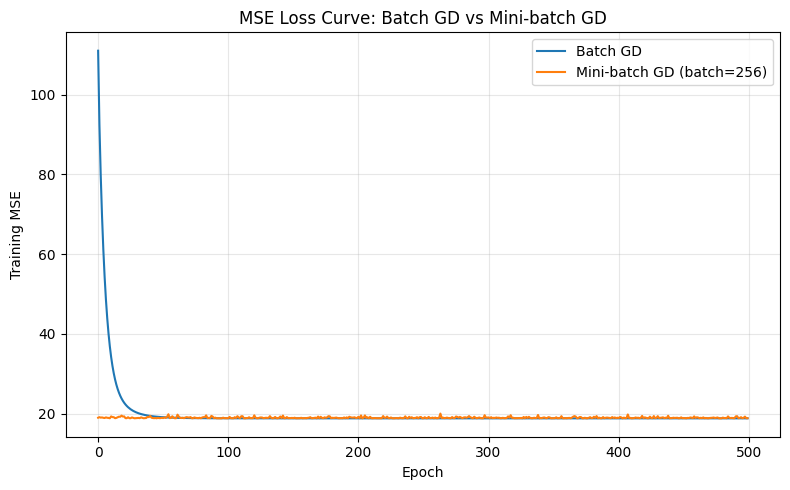


=== RMSE Comparison ===
Method                 Test RMSE
Batch GD                  4.4105
Mini-batch GD             4.4190
sklearn LinearReg         4.4105


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error


# Step 1: Load data

df = pd.read_csv("/content/placement_predict_50k Dataset.csv")

FEATURES = [
    "CGPA",
    "AttendancePercent",
    "Internships",
    "Projects",
    "Workshops",
    "Certifications",
    "Publications",
    "AptitudeTestScore",
    "SoftSkillsRating",
    "CodingTestScore",
    "MockInterviewScore",
    "ExtraCurricular"
]

TARGET = "Salary Package"

data = df[FEATURES + [TARGET]].copy()

# Fill missing values with median
data[FEATURES] = data[FEATURES].fillna(data[FEATURES].median())

X = data[FEATURES].values
y = data[TARGET].values.reshape(-1, 1)


# Step 2: Train/test split + scaling

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

scaler = StandardScaler()

X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

n_samples, n_features = X_train_s.shape

# Add bias/intercept column
X_train_b = np.hstack([
    np.ones((n_samples, 1)),
    X_train_s
])

X_test_b = np.hstack([
    np.ones((X_test_s.shape[0], 1)),
    X_test_s
])


# Step 3: Batch Gradient Descent

def compute_mse(X, y, theta):
    preds = X @ theta
    errors = preds - y
    return np.mean(errors ** 2)


def batch_gradient_descent(
    X,
    y,
    lr=0.05,
    n_epochs=500
):
    m, n = X.shape

    theta = np.zeros((n, 1))
    loss_history = []

    for epoch in range(n_epochs):

        preds = X @ theta

        errors = preds - y

        gradient = (2 / m) * (X.T @ errors)

        theta -= lr * gradient

        loss_history.append(
            compute_mse(X, y, theta)
        )

    return theta, loss_history


theta_gd, loss_history_gd = batch_gradient_descent(
    X_train_b,
    y_train,
    lr=0.05,
    n_epochs=500
)

rmse_gd = np.sqrt(
    compute_mse(
        X_test_b,
        y_test,
        theta_gd
    )
)

print(f"[Batch GD] Test RMSE = {rmse_gd:.4f}")


# Step 4: sklearn comparison

sk_model = LinearRegression()

sk_model.fit(
    X_train_s,
    y_train
)

y_pred_sk = sk_model.predict(X_test_s)

rmse_sklearn = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_sk
    )
)

print(
    f"[sklearn LR] Test RMSE = {rmse_sklearn:.4f}"
)

print(
    f"Difference (GD - sklearn) = "
    f"{rmse_gd - rmse_sklearn:.6f}"
)


# Step 5: Mini-batch Gradient Descent

def mini_batch_gradient_descent(
    X,
    y,
    lr=0.05,
    n_epochs=500,
    batch_size=256,
    seed=42
):

    m, n = X.shape

    theta = np.zeros((n, 1))

    loss_history = []

    rng = np.random.default_rng(seed)

    for epoch in range(n_epochs):

        indices = rng.permutation(m)

        X_shuffled = X[indices]
        y_shuffled = y[indices]

        for start in range(0, m, batch_size):

            end = start + batch_size

            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]

            preds = X_batch @ theta

            errors = preds - y_batch

            gradient = (
                2 / X_batch.shape[0]
            ) * (X_batch.T @ errors)

            theta -= lr * gradient

        loss_history.append(
            compute_mse(X, y, theta)
        )

    return theta, loss_history


theta_mb, loss_history_mb = mini_batch_gradient_descent(
    X_train_b,
    y_train,
    lr=0.05,
    n_epochs=500,
    batch_size=256
)

rmse_mb = np.sqrt(
    compute_mse(
        X_test_b,
        y_test,
        theta_mb
    )
)

print(
    f"[Mini-batch GD] Test RMSE = {rmse_mb:.4f}"
)


# Step 6: Plot loss curves

plt.figure(figsize=(8, 5))

plt.plot(
    loss_history_gd,
    label="Batch GD"
)

plt.plot(
    loss_history_mb,
    label="Mini-batch GD (batch=256)"
)

plt.xlabel("Epoch")
plt.ylabel("Training MSE")

plt.title(
    "MSE Loss Curve: Batch GD vs Mini-batch GD"
)

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig("loss_curve.png",
    dpi=150
)

plt.show()


# Step 7: Summary table

print("\n=== RMSE Comparison ===")

print(
    f"{'Method':<20}{'Test RMSE':>12}"
)

print(
    f"{'Batch GD':<20}{rmse_gd:>12.4f}"
)

print(
    f"{'Mini-batch GD':<20}{rmse_mb:>12.4f}"
)

print(
    f"{'sklearn LinearReg':<20}{rmse_sklearn:>12.4f}"
)